# Problem: Spectral clustering of data

Construct a weighted similarity graph from a small two-
dimensional data set. Compute its normalized Laplacian, inspect the first few eigenvectors, and compare
a spectral-clustering partition with 𝑘-means applied directly to the original data. Discuss the effect of
changing the kernel scale or neighbourhood size, and explain how a poor graph construction can distort
the resulting embedding.

# Exercise solution: Spectral clustering of a two-dimensional data set
We will use a synthetic data set consisting of two interleaving half-moons. This is a particularly useful example because the clusters are non-convex: ordinary $k$-means tends to fail, whereas spectral clustering can recover the underlying structure by exploiting local neighbourhood relationships.

The solution demonstrates:
1. Construction of a weighted similarity graph.
2. Computation of the normalized graph Laplacian.
3. Analysis of its eigenvalues and eigenvectors.
4. Spectral clustering and comparison with ordinary $k$-means.
5. Sensitivity to kernel scale and neighbourhood size.
6. The consequences of a poorly constructed graph.

## 1. Mathematical formulation
Let the data set be
$$
X=\{x_1,\ldots,x_n\},\qquad x_i\in\mathbb{R}^2.
$$

We construct a weighted undirected graph $G=(V,E,W)$.

For each data point, we identify its $k$ nearest neighbours. We assign Gaussian similarity weights:
$$
w_{ij}=
\begin{cases}
\exp\left(-\dfrac{\|x_i-x_j\|^2}{2\sigma^2}\right), & \text{if } i,j \text{ are neighbours}, \\
0, & \text{otherwise}.
\end{cases}
$$

We symmetrize the graph using
$$
W \leftarrow \max(W, W^\top).
$$

The degree matrix is
$$
D=\operatorname{diag}(d_1,\ldots,d_n),\qquad d_i=\sum_j w_{ij}.
$$

We use the symmetric normalized graph Laplacian:
$$
\boxed{L_{\mathrm{sym}}=I-D^{-1/2}WD^{-1/2}}
$$

Its eigenvalue problem is
$$
L_{\mathrm{sym}}u_i=\lambda_i u_i,
$$

with eigenvalues ordered as
$$
0=\lambda_1\leq\lambda_2\leq\cdots\leq\lambda_n.
$$

For two clusters, we use the first two eigenvectors, normalize the rows of their eigenvector matrix, and apply $k$-means to this spectral embedding.

Kernel scale sigma: 0.11853517642409317

First six eigenvalues:
[1.48286128e-17 3.18623819e-04 2.77808784e-03 3.85911003e-03
 1.07011143e-02 1.53853965e-02]

Degree statistics:
Minimum degree: 1.402830605866583
Maximum degree: 9.170710543342068

Number of connected components: 1

Adjusted Rand Index:
Ordinary k-means: 0.28143874715365647
Spectral clustering: 1.0


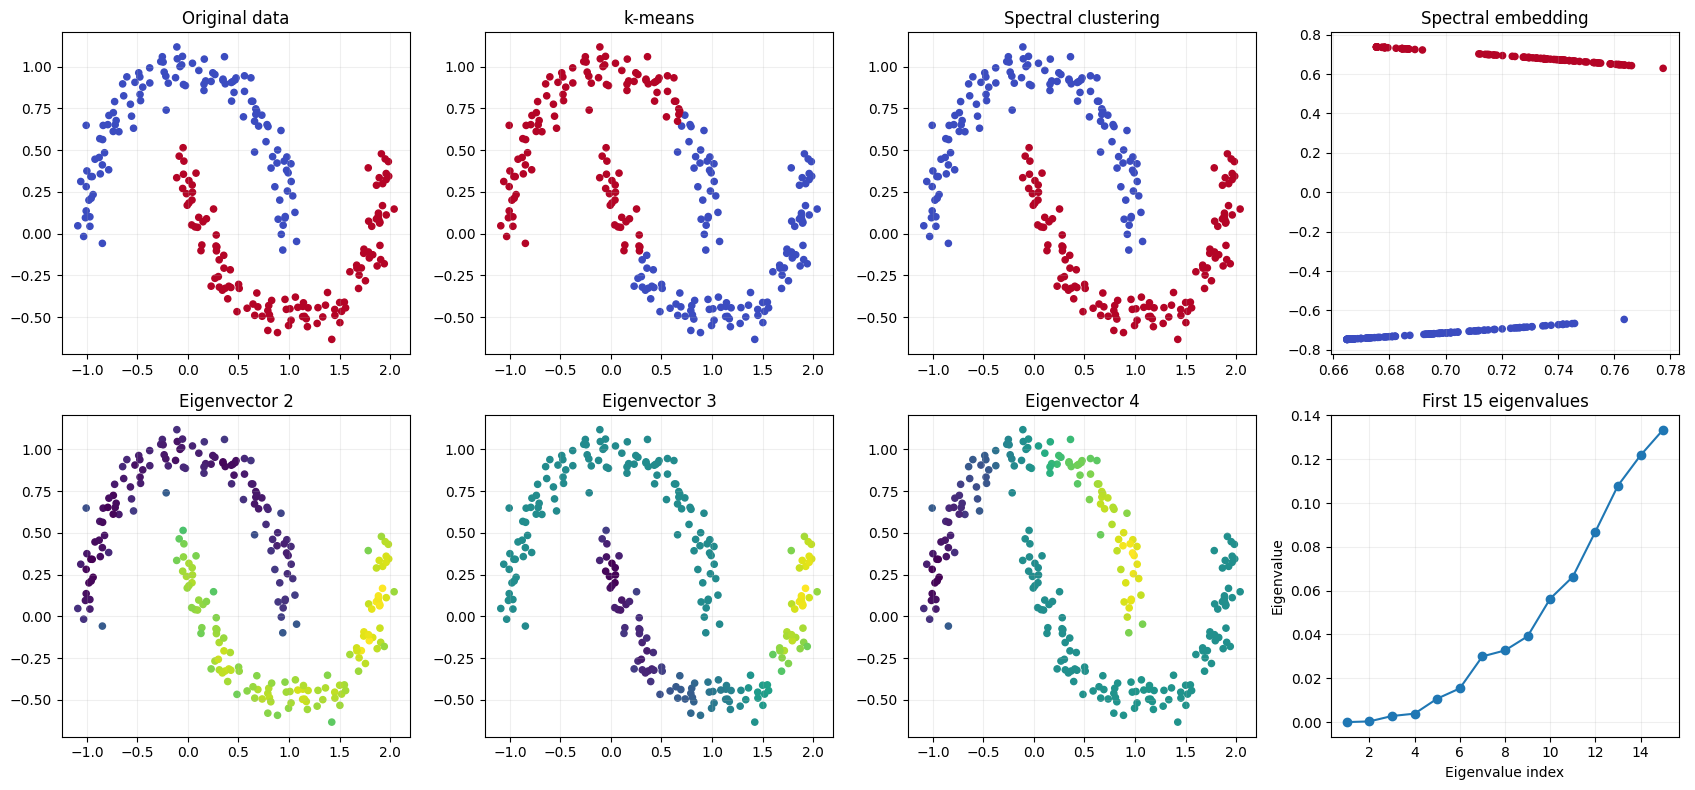

In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from scipy.sparse.csgraph import connected_components


# ---------------------------------------------------------
# 1. Generate a two-dimensional data set
# ---------------------------------------------------------

X, y_true = make_moons(
    n_samples=240,
    noise=0.07,
    random_state=7
)

n = len(X)
n_clusters = 2


# ---------------------------------------------------------
# 2. Construct a weighted k-nearest-neighbour graph
# ---------------------------------------------------------

def construct_graph(X, k=10, sigma_factor=1.0):

    # Find k nearest neighbours (excluding the point itself)
    distances, indices = NearestNeighbors(
        n_neighbors=k + 1
    ).fit(X).kneighbors(X)

    # Use median neighbour distance as reference scale
    sigma = sigma_factor * np.median(distances[:, 1:])

    W = np.zeros((len(X), len(X)))

    # Gaussian similarity weights
    for i in range(len(X)):
        for j, distance in zip(
            indices[i, 1:],
            distances[i, 1:]
        ):
            W[i, j] = np.exp(
                -distance**2 / (2 * sigma**2)
            )

    # Symmetrize: union of directed kNN relationships
    W = np.maximum(W, W.T)

    # No self-loops
    np.fill_diagonal(W, 0)

    return W, sigma


# ---------------------------------------------------------
# 3. Compute the normalized graph Laplacian
# ---------------------------------------------------------

def normalized_laplacian(W):

    degrees = W.sum(axis=1)

    if np.any(degrees == 0):
        raise ValueError(
            "Graph contains isolated vertices. "
            "Increase the neighbourhood size."
        )

    D_inv_sqrt = np.diag(1.0 / np.sqrt(degrees))

    L = (
        np.eye(len(W))
        - D_inv_sqrt @ W @ D_inv_sqrt
    )

    return L, degrees


# ---------------------------------------------------------
# 4. Spectral clustering
# ---------------------------------------------------------

def spectral_clustering(W, n_clusters=2):

    L, degrees = normalized_laplacian(W)

    # Symmetric eigensolver; eigenvalues are ascending
    eigenvalues, eigenvectors = np.linalg.eigh(L)

    # First n_clusters eigenvectors
    U = eigenvectors[:, :n_clusters]

    # Normalize rows of spectral embedding
    row_norms = np.linalg.norm(U, axis=1, keepdims=True)

    Y = U / np.maximum(row_norms, 1e-12)

    # Cluster in spectral embedding space
    labels = KMeans(
        n_clusters=n_clusters,
        n_init=30,
        random_state=7
    ).fit_predict(Y)

    return labels, eigenvalues, eigenvectors, Y, degrees


# ---------------------------------------------------------
# 5. Construct graph and perform spectral clustering
# ---------------------------------------------------------

k = 10
sigma_factor = 1.0

W, sigma = construct_graph(
    X,
    k=k,
    sigma_factor=sigma_factor
)

labels_spectral, eigenvalues, eigenvectors, Y, degrees = (
    spectral_clustering(W, n_clusters)
)

print("Kernel scale sigma:", sigma)

print("\nFirst six eigenvalues:")
print(eigenvalues[:6])

print("\nDegree statistics:")
print("Minimum degree:", degrees.min())
print("Maximum degree:", degrees.max())

n_components, component_labels = connected_components(
    W > 0,
    directed=False
)

print("\nNumber of connected components:", n_components)


# ---------------------------------------------------------
# 6. Ordinary k-means on original data
# ---------------------------------------------------------

labels_kmeans = KMeans(
    n_clusters=2,
    n_init=30,
    random_state=7
).fit_predict(X)


# ---------------------------------------------------------
# 7. Quantitative comparison
# ---------------------------------------------------------

ari_kmeans = adjusted_rand_score(
    y_true, labels_kmeans
)

ari_spectral = adjusted_rand_score(
    y_true, labels_spectral
)

print("\nAdjusted Rand Index:")
print("Ordinary k-means:", ari_kmeans)
print("Spectral clustering:", ari_spectral)


# ---------------------------------------------------------
# 8. Visualize the results
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 4, figsize=(17, 8))

# Original data and ground-truth labels
axes[0, 0].scatter(
    X[:, 0], X[:, 1],
    c=y_true, cmap="coolwarm", s=20
)
axes[0, 0].set_title("Original data")

# Ordinary k-means
axes[0, 1].scatter(
    X[:, 0], X[:, 1],
    c=labels_kmeans, cmap="coolwarm", s=20
)
axes[0, 1].set_title("k-means")

# Spectral clustering
axes[0, 2].scatter(
    X[:, 0], X[:, 1],
    c=labels_spectral, cmap="coolwarm", s=20
)
axes[0, 2].set_title("Spectral clustering")

# Spectral embedding
axes[0, 3].scatter(
    Y[:, 0], Y[:, 1],
    c=labels_spectral, cmap="coolwarm", s=20
)
axes[0, 3].set_title("Spectral embedding")

# Inspect the first three nontrivial eigenvectors
for j in range(1, 4):

    axes[1, j - 1].scatter(
        X[:, 0], X[:, 1],
        c=eigenvectors[:, j],
        cmap="viridis",
        s=20
    )

    axes[1, j - 1].set_title(
        f"Eigenvector {j + 1}"
    )

# Eigenvalue spectrum
axes[1, 3].plot(
    np.arange(1, 16),
    eigenvalues[:15],
    marker="o"
)

axes[1, 3].set_title("First 15 eigenvalues")
axes[1, 3].set_xlabel("Eigenvalue index")
axes[1, 3].set_ylabel("Eigenvalue")

for ax in axes.flat:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


The important observation is that ordinary \(k\)-means partitions the original Euclidean space into approximately convex regions. It therefore struggles to identify the two curved moons.

Spectral clustering transforms the problem into a different geometric space, where the first eigenvectors encode the connectivity structure of the similarity graph.
### Interpretation of the eigenvectors
The first eigenvector corresponds to the smallest eigenvalue:
$$
\lambda_1=0.
$$

For a connected graph,
$$
u_1\propto D^{1/2}\mathbf 1.
$$

It therefore primarily describes the degree distribution.

The second eigenvector, associated with \(\lambda_2\), is the Fiedler-type eigenvector of the normalized Laplacian. It captures a low-frequency variation across the graph and is particularly important for identifying a partition.

The third and subsequent eigenvectors describe progressively more complicated variations in the graph.

An important point for the exercise: eigenvectors are defined only up to sign, and eigenvectors within a repeated or nearly repeated eigenspace can rotate. Their interpretation should therefore focus on the corresponding eigenspace rather than the sign or precise appearance of an individual eigenvector.

# Discussion: Parameter Sensitivity and Graph Distortion

In spectral clustering, the quality of the clustering depends entirely on how well the similarity graph represents the underlying manifold structure of the data. The two key parameters controlling this are the **neighbourhood size ($k$)** and the **kernel scale ($\sigma$).**

---

### 1. The Effect of the Kernel Scale ($\sigma$)

The parameter $\sigma$ determines the width of the Gaussian radial basis function (RBF) kernel, which maps distance to similarity:
$$
w_{ij} = \exp\left(-\frac{\|x_i - x_j\|^2}{2\sigma^2}\right)
$$

* **$\sigma$ is too small (Under-connectivity):**  
  If $\sigma \to 0$, the similarity decay is extremely steep. Even slightly distant points within the same cluster will have near-zero similarity. The graph effectively disconnects into many isolated nodes or tiny sub-components. The Laplacian matrix's lowest eigenvalues will all flatten toward 0, making it impossible to identify the true global clusters.
* **$\sigma$ is too large (Over-connectivity):**  
  If $\sigma \to \infty$, the similarity $w_{ij}$ approaches $1$ for nearly all pairs of adjacent nodes, regardless of their distance. This washes out the local geometry. The graph loses its capacity to distinguish between nearby points and distant points across separate clusters, collapsing the spectral embedding into a dense ball where the two half-moons overlap.

---

### 2. The Effect of the Neighbourhood Size ($k$)

The parameter $k$ controls the density and sparseness of the graph adjacency structure.

* **$k$ is too small:**  
  The graph is highly disconnected. If the number of connected components is greater than the target number of clusters ($n_c$), the first $n_c$ eigenvectors will simply be step functions indicating membership in these arbitrary connected subgraphs, completely losing the macroscopic shape of the manifold.
* **$k$ is too large:**  
  The graph starts to contain many "spurious" edges that bridge the gap between the two separate half-moons. As $k \to n$, the graph approaches a fully connected graph. This forces the graph Laplacian to capture global distances rather than local manifold geodesic distances, causing spectral clustering to fail and behave exactly like ordinary $k$-means on the original Euclidean coordinates.

---

### 3. Visualizing Distortion from Poor Graph Construction

* **Well-constructed Graph (e.g., $k=10$, $\sigma = 1.0 \times \text{median}$):**  
  The spectral embedding maps the points onto clean, distinct structures (as seen in the `Spectral embedding` plot, where the two moons map onto orthogonal-like line segments). This makes them easily separable by linear boundaries or $k$-means.
* **Poorly-constructed Graph (e.g., $k=30$):**  
  Spurious connections across the gap between the moons contaminate the graph Laplacian. Consequently, the second eigenvector will no longer represent the clean partition of the two moons but will instead oscillate along the combined length of the dataset, producing a distorted embedding where points from different clusters are completely mixed.

## 4. Influence of kernel scale and neighbourhood size
The graph construction involves two important parameters:
- $k$: number of nearest neighbours.
- $\sigma$: Gaussian kernel scale.

We now investigate how changing these parameters affects the spectral clustering result.


In [2]:

# ---------------------------------------------------------
# 9. Parameter sensitivity analysis
# ---------------------------------------------------------

def evaluate_graph(X, y_true, k, sigma_factor):

    W, sigma = construct_graph(
        X, k=k, sigma_factor=sigma_factor
    )

    labels, eigenvalues, U, Y, degrees = (
        spectral_clustering(W, n_clusters=2)
    )

    n_components, _ = connected_components(
        W > 0, directed=False
    )

    ari = adjusted_rand_score(y_true, labels)

    return {
        "k": k,
        "sigma_factor": sigma_factor,
        "sigma": sigma,
        "components": n_components,
        "lambda_2": eigenvalues[1],
        "lambda_3": eigenvalues[2],
        "ARI": ari
    }


# Vary kernel scale
print("\nInfluence of kernel scale")

for sf in [0.5, 1.0, 2.0]:

    result = evaluate_graph(X, y_true, 10, sf)

    print(result)


# Vary neighbourhood size
print("\nInfluence of neighbourhood size")

for k_test in [5, 10, 20, 30]:

    result = evaluate_graph(X, y_true, k_test, 1.0)

    print(result)



Influence of kernel scale
{'k': 10, 'sigma_factor': 0.5, 'sigma': np.float64(0.059267588212046585), 'components': 1, 'lambda_2': np.float64(1.2526355889639254e-07), 'lambda_3': np.float64(0.0004331150361104179), 'ARI': 1.0}
{'k': 10, 'sigma_factor': 1.0, 'sigma': np.float64(0.11853517642409317), 'components': 1, 'lambda_2': np.float64(0.00031862381889741475), 'lambda_3': np.float64(0.002778087843513797), 'ARI': 1.0}
{'k': 10, 'sigma_factor': 2.0, 'sigma': np.float64(0.23707035284818634), 'components': 1, 'lambda_2': np.float64(0.0014262209850238975), 'lambda_3': np.float64(0.004352364844601962), 'ARI': 1.0}

Influence of neighbourhood size
{'k': 5, 'sigma_factor': 1.0, 'sigma': np.float64(0.0791911946641321), 'components': 5, 'lambda_2': np.float64(2.341250413646052e-18), 'lambda_3': np.float64(3.8083866497020407e-16), 'ARI': 0.5990322436666571}
{'k': 10, 'sigma_factor': 1.0, 'sigma': np.float64(0.11853517642409317), 'components': 1, 'lambda_2': np.float64(0.00031862381889741475), 'la

These results illustrate several important phenomena.

### Effect of kernel scale
- Small $\sigma$: similarities decay rapidly. The graph becomes dominated by very local relationships.
- Large $\sigma$: similarities become more uniform. Differences between nearby and distant points become less pronounced.
- Intermediate $\sigma$: the graph can preserve local geometry while maintaining meaningful connectivity.

In this example, clustering remains accurate over a relatively broad range of kernel scales. This is not guaranteed for other data sets.

### Effect of neighbourhood size
- Small $k$: the graph can become disconnected. This introduces multiple zero eigenvalues and makes the spectral embedding ambiguous.
- Large $k$: additional, potentially inappropriate connections may appear between different clusters.
- Intermediate $k$: a useful compromise between local geometric information and global connectivity.

Notice that for $k=5$, the graph has five connected components. Consequently, its normalized Laplacian has five zero eigenvalues. Selecting only the first two eigenvectors does not provide a meaningful two-cluster embedding in this case. The reported ARI should therefore be interpreted cautiously.
## 5. How poor graph construction distorts the embedding
This is arguably the most important conceptual part of the exercise.

Spectral clustering does not discover the geometry of the data independently of the graph. It discovers the geometry encoded by the graph we construct.

There are several failure mechanisms.
Graph construction problem	Spectral consequence
Too few neighbours	Disconnected graph, multiple zero eigenvalues
Too many neighbours	Artificial connections between clusters
Kernel scale too small	Extremely weak edges and poor numerical conditioning
Kernel scale too large	Loss of local geometric discrimination
Nonuniform sampling density	Degree variations distort the normalized embedding
Outliers	Artificial bridges or isolated components

Consider the Laplacian eigenvalue problem:
$$
L_{\mathrm{sym}}u=\lambda u.
$$

The eigenvectors are determined entirely by $W$ and $D$.

If the graph contains an artificial bridge between two otherwise separate structures, the corresponding eigenvectors may reflect that bridge rather than the actual geometry of the data.

Conversely, if the graph is disconnected, the multiplicity of the zero eigenvalue reflects the number of connected components, not necessarily the number of meaningful clusters.

This distinction is essential: graph connectivity and data clustering are related, but they are not identical concepts.

## 6. Further mathematical interpretation
The normalized Laplacian has a useful variational interpretation.

For a vector $f$, define
$$
g=D^{-1/2}f.
$$

Then
$$
f^\top L_{\mathrm{sym}}f
=
\frac12\sum_{i,j}w_{ij}
(g_i-g_j)^2.
$$

Thus, eigenvectors associated with small eigenvalues minimize variation across strongly connected vertices.

This is the mathematical reason spectral clustering works:
- Strongly connected points tend to receive similar embedding coordinates.
- Weakly connected regions can acquire substantially different coordinates.
- The resulting embedding makes otherwise non-convex clusters easier to separate using \(k\)-means.

It also connects this exercise directly to the graph Laplacian and Dirichlet energy developed in Chapter 12.
## 7. Suggested conclusions for the exercise
A suitable written conclusion for students would be:

Spectral clustering provides a way to identify non-convex structures in data by exploiting the eigenvectors of a graph Laplacian. Unlike conventional $k$-means, which relies on Euclidean distances to cluster points directly, spectral clustering first constructs a weighted similarity graph and then transforms the data into a low-dimensional spectral embedding.

The quality of the resulting clustering depends critically on graph construction. The neighbourhood size and kernel scale determine which relationships are represented and how strongly they contribute to the Laplacian. A poorly constructed graph can introduce artificial connections, disconnect meaningful structures, or distort the resulting embedding.

The experiment demonstrates that eigenvectors of a suitably constructed graph Laplacian can reveal global structure that is difficult to identify using the original coordinates alone.


## 8. Connection to your book
I would emphasize three mathematical connections in the accompanying discussion in Chapter 12:
1. Chapter 2 — Matrix Analysis: The spectral decomposition of a real symmetric matrix and the properties of its eigenvectors.
2. Chapter 7 — Functional Analysis: The quadratic-form interpretation of the Laplacian and its connection to energy minimization.
3. Chapter 10 — Numerical Spectral Methods: Practical computation of eigenvalues and eigenvectors, including the use of Lanczos or Arnoldi methods for larger graphs.

For larger data sets, the dense eigendecomposition in this example should be replaced by a sparse Laplacian and a sparse eigensolver such as scipy.sparse.linalg.eigsh.

One particularly worthwhile extension: compare the standard symmetric normalized Laplacian with the random-walk Laplacian
$$
L_{\mathrm{rw}}=I-D^{-1}W
$$

and investigate how nonuniform sampling density affects the two spectral embeddings. This would make an excellent advanced extension of the exercise.

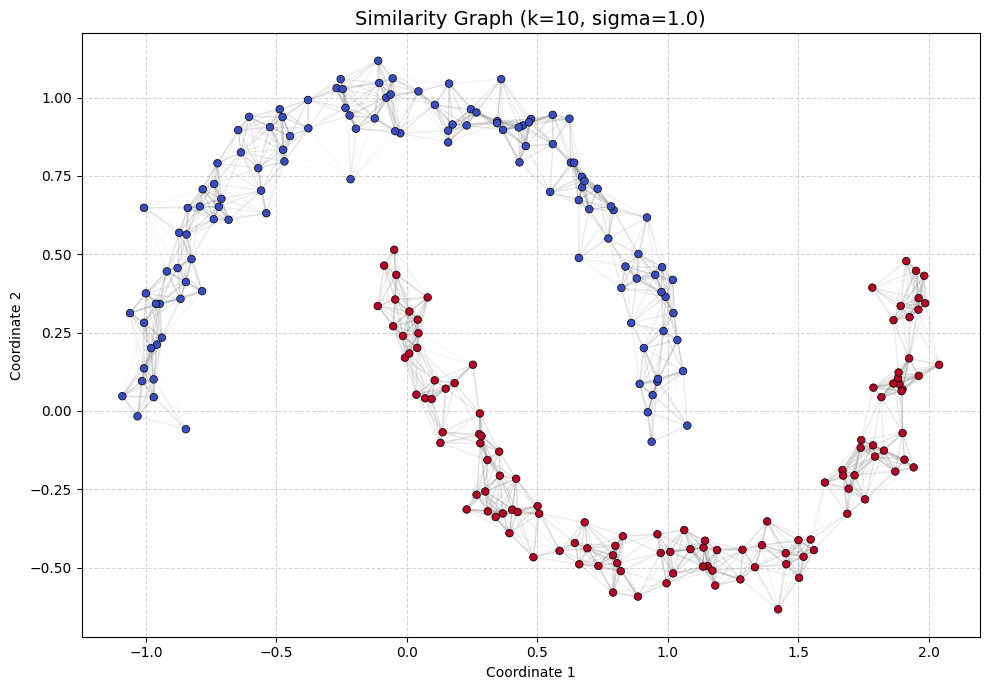

In [3]:
# ---------------------------------------------------------
# Visualizing the Constructed Similarity Graph
# ---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neighbors import NearestNeighbors

def construct_graph(X, k=10, sigma_factor=1.0):
    # Find k nearest neighbours (excluding the point itself)
    distances, indices = NearestNeighbors(
        n_neighbors=k + 1
    ).fit(X).kneighbors(X)

    # Use median neighbour distance as reference scale
    sigma = sigma_factor * np.median(distances[:, 1:])

    W = np.zeros((len(X), len(X)))

    # Gaussian similarity weights
    for i in range(len(X)):
        for j, distance in zip(
            indices[i, 1:],
            distances[i, 1:]
        ):
            W[i, j] = np.exp(
                -distance**2 / (2 * sigma**2)
            )

    # Symmetrize: union of directed kNN relationships
    W = np.maximum(W, W.T)

    # No self-loops
    np.fill_diagonal(W, 0)

    return W, sigma

def plot_similarity_graph(X, W, title="Similarity Graph (k=10, sigma=1.0)"):
    plt.figure(figsize=(10, 7))

    # Plot nodes colored by ground truth labels
    plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap='coolwarm', s=30, zorder=3, edgecolors='k', linewidth=0.5)

    # Get index pairs for non-zero connections in the upper triangle of similarity matrix W
    sources, targets = np.nonzero(np.triu(W))

    # Plot the lines between connected nodes
    for src, tgt in zip(sources, targets):
        weight = W[src, tgt]
        # We can map the weight to line transparency (alpha) to visualize connection strength
        plt.plot(
            [X[src, 0], X[tgt, 0]],
            [X[src, 1], X[tgt, 1]],
            color='gray',
            alpha=float(weight * 0.4),
            linewidth=1.0,
            zorder=2
        )

    plt.title(title, fontsize=14)
    plt.xlabel("Coordinate 1")
    plt.ylabel("Coordinate 2")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# Ensure components are generated if the kernel was restarted
X, y_true = make_moons(
    n_samples=240,
    noise=0.07,
    random_state=7
)
W, sigma = construct_graph(X, k=10, sigma_factor=1.0)

# Generate the plot with the constructed graph W
plot_similarity_graph(X, W)